In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.integrate import quad
from scipy.optimize import minimize
from IPython.display import display
import rearrangement_algorithm as ra

%load_ext autoreload
%autoreload 2
%matplotlib inline

# Case 5: Nonnegative asset capacities, $d=20$
**Stage 1:** Worst-case aggregate bid under unrestricted dependence (RA).  
**Stage 2A:** Dependence-robust fixed allocation (no redispatch): maximum jointly deliverable bid, and best allocation of the Stage 1 aggregate bid.

## 1. Marginal distribution assumptions
The fixed `mu` and `sd` describe latent Gaussian variables, not the moments of transformed capacities.

- **Ordinary assets:** $X_i=\max(0,Y_i)$ with $Y_i\sim N(\mu_i,\sigma_i^2)$, so $P(X_i=0)=\Phi(-\mu_i/\sigma_i)$.
- **Outage-risk assets:** $X_i=B_iY_i^+$ with $P(B_i=0)=p_{\rm outage}$ and $Y_i^+\sim N(\mu_i,\sigma_i^2)\mid Y_i>0$, giving *exactly* $P(X_i=0)=p_{\rm outage}$.

Both types have support in $[0,\infty)$, and marginal quantile functions remain analytic. **P90 capacity** is the lower 10% quantile, which is exceeded with probability at least 90%.

In [2]:
class CapacityMarginal:
    def __init__(self, mu, sd, asset_type='ordinary', p_outage=0.05):
        if sd <= 0 or asset_type not in ('ordinary', 'outage') or not 0 <= p_outage < 1:
            raise ValueError('Invalid marginal parameters')
        self.mu, self.sd, self.asset_type = float(mu), float(sd), asset_type
        self.p_outage = float(p_outage)
        self.positive = stats.truncnorm(-self.mu/self.sd, np.inf, loc=self.mu, scale=self.sd)
        self.prob_zero = (float(stats.norm.cdf(-self.mu/self.sd))
                          if asset_type == 'ordinary' else self.p_outage)

    def cdf(self, x):
        x = np.asarray(x, dtype=float)
        if self.asset_type == 'ordinary':
            value = stats.norm.cdf(x, loc=self.mu, scale=self.sd)
        else:
            value = self.p_outage + (1-self.p_outage)*self.positive.cdf(x)
        return np.where(x < 0, 0., value)

    def ppf(self, u):
        u = np.asarray(u, dtype=float)
        if np.any((u < 0) | (u > 1) | ~np.isfinite(u)):
            raise ValueError('Quantile probabilities must be in [0, 1]')
        if self.asset_type == 'ordinary':
            return np.maximum(0., stats.norm.ppf(u, loc=self.mu, scale=self.sd))
        v = np.clip((u-self.p_outage)/(1-self.p_outage), 0., 1.)
        return np.where(u <= self.p_outage, 0., np.maximum(0., self.positive.ppf(v)))

    def sample(self, n, rng):
        return self.ppf(rng.random(n))

    def failure(self, c):
        # P(X < c) = F(c-); the only atom is at zero.
        c = np.asarray(c, dtype=float)
        return np.where(c <= 0, 0., self.cdf(c))

## 2. Scenario configuration
Change `scenario` and run all cells. Both portfolios are evaluated with identical latent parameters and simulation seeds for comparison.

In [3]:
seed = 0
rng = np.random.default_rng(seed)
d = 50
mu = rng.normal(loc=10, scale=4, size=d)
sd = rng.uniform(0.5, 5, size=d)
a = np.ones(d)
alpha = 0.9
eps = 0.1
scenario = 'ordinary'  # 'ordinary' or 'mixed'
outage_indices = [0, 1, 2, 3, 4]
p_outage = 0.05
rho = 0.5
n_sim = 100_000
num_steps = 10_000

def build_marginals(name):
    if name not in ('ordinary', 'mixed'):
        raise ValueError('Unknown scenario')
    if (len(outage_indices) != 5 or len(set(outage_indices)) != 5
            or any(not isinstance(i, (int, np.integer)) or not 0 <= i < d for i in outage_indices)):
        raise ValueError('Choose exactly five distinct asset indices in [0, 19]')
    return [CapacityMarginal(mu[i], sd[i],
             'outage' if name == 'mixed' and i in outage_indices else 'ordinary', p_outage)
            for i in range(d)]

portfolios = {name: build_marginals(name) for name in ('ordinary', 'mixed')}
marginals = portfolios[scenario]

def marginal_table(ms):
    return pd.DataFrame({'Asset': np.arange(d), 'Type': [m.asset_type for m in ms],
        'Latent mean': mu, 'Latent SD': sd,
        'P90 capacity': [m.ppf(eps).item() for m in ms],
        'Probability at zero': [m.prob_zero for m in ms]})

# for name, ms in portfolios.items():
#     print(name)
#     display(marginal_table(ms))

In [4]:
scenario = "ordinary"
portfolios = {scenario: build_marginals(scenario)}
marginals = portfolios[scenario]

## 4. Dependence assumptions
Compare comonotonicity, independence, a Gaussian copula with $\rho=0.5$, and unrestricted dependence via RA.
The Gaussian correlation matrix describes latent copula normals; it is **not** the capacity correlation matrix after transformation.
Normal CDF/quantile calls below apply only to latent copula variables.
The Bernoulli/positive-draw independence specifies each marginal; cross-asset dependence is imposed through the selected copula.

In [5]:
def corr_eq(d, rho):
    if d < 1 or not (-1/(d-1) if d > 1 else -1) <= rho <= 1:
        raise ValueError('Invalid equicorrelation')
    return np.full((d, d), rho) + (1-rho)*np.eye(d)

Sigma = corr_eq(d, rho)

def capacities(U, ms):
    return np.column_stack([m.ppf(U[:, i]) for i, m in enumerate(ms)])

# Common random numbers across scenarios; distinct independent/copula streams.
U_ind = np.random.default_rng(seed+1).random((n_sim, d))
latent = np.random.default_rng(seed+2).multivariate_normal(np.zeros(d), Sigma, size=n_sim)
U_copula = stats.norm.cdf(latent)

## 5. Stage 1: Robust aggregate bid
Comonotonic aggregate VaR is the sum of marginal lower-tail quantiles. Independent and Gaussian-copula VaRs are Monte Carlo estimates, not Gaussian closed forms.
RA receives the actual marginal quantiles, including flat zero segments. Its returned bracket and gap are retained; finite discretization and stopping tolerance limit numerical accuracy. No jitter is added to atoms.

In [6]:
def stage1(ms):
    qf = [m.ppf for m in ms]  # unit weights a_i = 1
    lower, upper = ra.bounds_VaR(eps, qf, method='lower', num_steps=num_steps, abstol=1e-8)
    lo, hi = float(lower[0]), float(upper[0])
    if not np.isfinite([lo, hi]).all() or lo > hi + 1e-7:
        raise RuntimeError('Invalid RA numerical bracket')
    Xi, Xg = capacities(U_ind, ms), capacities(U_copula, ms)
    assert np.all(Xi >= 0) and np.all(Xg >= 0)
    return dict(comonotonic=sum(m.ppf(eps).item() for m in ms),
                independent=float(np.quantile(Xi.sum(axis=1), eps)),
                gaussian=float(np.quantile(Xg.sum(axis=1), eps)),
                ra_lower=lo, ra_upper=hi, ra_gap=hi-lo)

bids = {name: stage1(ms) for name, ms in portfolios.items()}
VaR_X = np.array([m.ppf(eps).item() for m in marginals])
VaR_worst_lo, VaR_worst_hi = bids[scenario]['ra_lower'], bids[scenario]['ra_upper']
print(f'{scenario}: RA bracket [{VaR_worst_lo:.6f}, {VaR_worst_hi:.6f}]')

ordinary: RA bracket [268.437695, 268.470805]


## 6. Stage 2A — Dependence-robust allocation **without redispatch**
Let $c_i\ge 0$ be the *fixed* commitment of asset $i$. Its marginal failure probability is

$$f_i(c_i)=P(X_i<c_i)=F_i(c_i^-).$$

The left limit matters because $P(X_i=0)>0$: **$f_i(0)=0$** (a zero commitment never fails); for $c_i>0$, $f_i(c_i)=F_i(c_i)$.

For unrestricted dependence, the sharp Fréchet lower bound on joint success is

$$\underline S(\mathbf c)=\inf_{C}P_C(X_i\ge c_i\;\forall i)
=\max\!\left\{0,1-\sum_{i=1}^d f_i(c_i)\right\}.$$

### Problem A: largest bid that needs no redispatch

$$\boxed{b_{\rm joint}^*=\max_{\mathbf c\ge0}\left\{\sum_i c_i:\sum_i f_i(c_i)\le\epsilon\right\}}.$$

Compare with the Stage 1 robust aggregate bid $b_{\rm agg}^*$:

$$\Delta b=b_{\rm agg}^*-b_{\rm joint}^*\ge0.$$

### Problem B: best *fixed allocation* of the Stage 1 bid

$$\boxed{\min_{\mathbf c\ge0}\sum_i f_i(c_i)\quad\text{s.t.}\quad\sum_i c_i=b_{\rm agg}^*.}$$

The resulting robust joint reliability is $\max\{0,1-\sum_i f_i(c_i^*)\}$. **This replaces the prior equal-increments heuristic.** Even when the best achievable reliability is below 90%, Problem B provides the least-risk fixed allocation at the aggregate bid.

### Numerical method and accuracy

Because $f_i$ jumps immediately to its zero-atom mass when $c_i>0$, this is a nonconvex allocation problem with implicit active/inactive asset decisions. We use a **multiple-choice mixed-integer linear program (MILP)** on a grid of per-asset marginal quantiles: each asset selects zero commitment or one strictly positive commitment. We optionally improve the selected active set by continuous SLSQP optimization. This recognizes zero allocations exactly.

The reported $b_{\rm joint}$ is a **feasible, discretization-dependent lower estimate** of the continuous optimum, not a globally certified continuous optimum. The reported fixed-bid allocation is a feasible candidate, not a proof of global optimality. Increase `n_grid_bid`/`n_grid_fixed`, and compare stability of results. Feasibility and reported reliability are checked using the **exact marginal CDFs**, not grid estimates. This analysis does *not* assume a Gaussian copula; Gaussian-copula survival is shown only as a comparison.


In [7]:
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import lil_matrix

# The Gaussian-copula function below is retained ONLY for comparison;
# optimization for Stage 2A uses the exact Fréchet lower bound.
def failures(c, ms):
    c = np.asarray(c, dtype=float)
    if c.shape != (len(ms),) or np.any(c < -1e-10):
        raise ValueError('Commitments must be a nonnegative vector')
    return np.array([m.failure(max(0., ci)).item() for ci, m in zip(c, ms)])

nodes, weights = np.polynomial.hermite.hermgauss(100)
factor = np.sqrt(2)*nodes
weights = weights/np.sqrt(np.pi)

def copula_survival_f(f, accurate=False):
    f = np.asarray(f)
    f = f[f > 0]  # Assets with zero commitment impose no survival constraint.
    if len(f) == 0:
        return 1.
    if np.any(f >= 1):
        return 0.
    z = stats.norm.ppf(f)
    def conditional(y):
        return np.prod(stats.norm.cdf((np.sqrt(rho)*y-z)/np.sqrt(1-rho)), axis=-1)
    if accurate:
        return quad(lambda y: stats.norm.pdf(y)*conditional(y), -np.inf, np.inf,
                    epsabs=1e-10, epsrel=1e-10)[0]
    return float(weights @ conditional(factor[:, None]))

def reliability_no_redispatch(c, ms):
    f = failures(c, ms)
    return dict(worst=max(0., 1-f.sum()), M=float((1-f).min()),
                Pi=float((1-f).prod()), gaussian=copula_survival_f(f, accurate=True))

n_grid_bid = 120     # discretization levels per asset for Problem A
n_grid_fixed = 130   # discretization levels per asset for Problem B
milp_time_limit = 60 # seconds PER optimization; feasible incumbents are acceptable

def _options(ms, mode, n_grid):
    # Each option is (committed capacity, strict shortfall probability).
    result = []
    for m in ms:
        p0 = m.prob_zero
        options = [(0., 0.)]  # Atomic point at c=0 must have zero shortfall cost.
        if mode == 'joint':
            if p0 < eps-1e-9:
                levels = np.linspace(p0+1e-9, eps, n_grid)
            else:
                levels = np.array([])
        elif mode == 'fixed':
            low = p0+1e-9
            mid = max(0.20, low)
            n_low = int(0.65*n_grid)
            levels = np.r_[np.linspace(low, mid, n_low),
                            np.linspace(mid, 0.995, n_grid-n_low)] if low < 0.995 else np.array([])
        else:
            raise ValueError('Unrecognized allocation optimization')
        for p in np.unique(levels):
            if not p0 < p < 1.:
                continue
            c = float(m.ppf(p))
            if np.isfinite(c) and c > 1e-9:
                options.append((c, float(m.failure(c))))
        result.append(options)
    return result

def _discrete_allocation(ms, mode, bid=None, n_grid=120, time_limit=None):
    options = _options(ms, mode, n_grid)
    n_assets = len(ms)
    counts = [len(x) for x in options]
    cap = np.array([x[0] for options_i in options for x in options_i])
    prob = np.array([x[1] for options_i in options for x in options_i])
    total = len(cap)
    A = lil_matrix((n_assets+1, total), dtype=float)
    start = 0
    for i, cnt in enumerate(counts):
        A[i, start:start+cnt] = 1.
        start += cnt
    if mode == 'joint':
        A[-1, :] = prob
        last_lb, last_ub = -np.inf, eps
        objective = -cap
    else:
        A[-1, :] = cap
        last_lb, last_ub = bid, np.inf
        objective = prob
    lb = np.r_[np.ones(n_assets), last_lb]
    ub = np.r_[np.ones(n_assets), last_ub]
    res = milp(objective, integrality=np.ones(total, dtype=int),
        bounds=Bounds(np.zeros(total), np.ones(total)),
        constraints=LinearConstraint(A.tocsr(), lb, ub),
        options={'time_limit': milp_time_limit if time_limit is None else time_limit,
                 'mip_rel_gap': 1e-5})
    if res.x is None:
        raise RuntimeError(f'MILP has no incumbent: {res.message}')
    # A feasible integer selection: one column option for each asset.
    selected = []
    start = 0
    for count in counts:
        sub = res.x[start:start+count]
        k = int(np.argmax(sub))
        if sub[k] < 1-1e-5:
            raise RuntimeError('MILP did not return a valid integral incumbent')
        selected.append(start+k)
        start += count
    c = cap[selected]
    fail = failures(c, ms)
    if mode == 'joint' and fail.sum() > eps+1e-8:
        raise RuntimeError('No-redispatch candidate violates the risk budget')
    if mode == 'fixed' and c.sum() < bid-1e-7:
        raise RuntimeError('Fixed-bid candidate falls short of the aggregate bid')
    return c, dict(status=res.message, mip_gap=getattr(res, 'mip_gap', None))

def _improve_joint(ms, c):
    # Polish capacities through failure-probability coordinates on the MILP active set.
    active = np.flatnonzero(c > 1e-9)
    if len(active) == 0:
        return c
    floor = np.array([ms[i].prob_zero for i in active])
    p_start = failures(c, ms)[active]
    if floor.sum() >= eps:
        return c
    def objective(p):
        return -sum(float(ms[i].ppf(v)) for i, v in zip(active, p))
    res = minimize(objective, p_start,
        bounds=list(zip(floor+1e-10, np.full(len(active), eps))),
        constraints=[dict(type='ineq', fun=lambda p: eps-p.sum())],
        method='SLSQP', options={'ftol': 1e-11, 'maxiter': 400})
    if np.any(~np.isfinite(res.x)):
        return c
    p = np.clip(res.x, floor+1e-10, eps)
    # Numerical feasibility projection even if SLSQP reports a line-search issue.
    if p.sum() > eps:
        p = floor+ (p-floor)*(eps-floor.sum())/(p-floor).sum()
    candidate = np.zeros(len(ms))
    candidate[active] = [ms[i].ppf(v).item() for i, v in zip(active, p)]
    if failures(candidate, ms).sum() <= eps+1e-9 and candidate.sum() > c.sum()+1e-8:
        return candidate
    return c

def _improve_fixed(ms, c, bid):
    # Optimize risk on selected positive assets while requiring the exact bid.
    c = np.asarray(c, dtype=float).copy()
    c *= bid/c.sum()  # MILP requirement is >= bid; reduce any overage.
    active = np.flatnonzero(c > 1e-9)
    if len(active) == 0:
        return c
    def objective(x):
        return sum(float(ms[i].failure(v)) for i, v in zip(active, x))
    res = minimize(objective, c[active], method='SLSQP',
        bounds=[(1e-9, bid) for _ in active],
        constraints=[dict(type='eq', fun=lambda x: x.sum()-bid)],
        options={'ftol': 1e-11, 'maxiter': 400})
    if res.success and np.all(np.isfinite(res.x)) and abs(sum(res.x)-bid) < 1e-6:
        candidate = np.zeros(len(ms))
        candidate[active] = res.x
        if failures(candidate, ms).sum() < failures(c, ms).sum()-1e-9:
            return candidate
    return c

# Solve both robust fixed-allocation problems independently, for both portfolios.
allocations = {}
for name, ms in portfolios.items():
    b_agg = bids[name]['ra_lower']
    c_joint, joint_info = _discrete_allocation(ms, 'joint', n_grid=n_grid_bid)
    c_joint = _improve_joint(ms, c_joint)
    c_fixed, fixed_info = _discrete_allocation(ms, 'fixed', bid=b_agg, n_grid=n_grid_fixed)
    c_fixed = _improve_fixed(ms, c_fixed, b_agg)
    b_joint = float(c_joint.sum())
    gap = float(b_agg-b_joint)
    allocations[name] = dict(
        b_agg=b_agg, b_joint=b_joint, gap=gap,
        joint_c=c_joint, joint_risk=failures(c_joint, ms).sum(),
        joint_reliability=reliability_no_redispatch(c_joint, ms),
        fixed_c=c_fixed, fixed_risk=failures(c_fixed, ms).sum(),
        fixed_reliability=reliability_no_redispatch(c_fixed, ms),
        joint_solver=joint_info, fixed_solver=fixed_info)
    if gap < -1e-5:
        raise RuntimeError('Optimized joint-only bid exceeds RA aggregate bound: check algorithms')
    if failures(c_joint, ms).sum() > eps+1e-8 or abs(c_fixed.sum()-b_agg) > 1e-6:
        raise RuntimeError('Stage 2A allocation infeasible')
    print(f'{name}: aggregate bid={b_agg:.4f}, no-redispatch joint bid≈{b_joint:.4f}, gap≈{gap:.4f}')
    print(f'  At aggregate bid: best-found robust survival={allocations[name]["fixed_reliability"]["worst"]:.4%}')
    display(pd.DataFrame({
        'Asset': np.arange(d), 'Type': [m.asset_type for m in ms],
        'P90': [m.ppf(eps).item() for m in ms],
        'Optimal joint-bid allocation': c_joint,
        'Optimal-at-aggregate-bid allocation': c_fixed,
        'Shortfall probability (joint bid)': failures(c_joint, ms),
        'Shortfall probability (aggregate bid)': failures(c_fixed, ms)}))


ordinary: aggregate bid=268.4377, no-redispatch joint bid≈160.3990, gap≈108.0387
  At aggregate bid: best-found robust survival=0.0000%


,Asset,Type,P90,Optimal joint-bid allocation,Optimal-at-aggregate-bid allocation,Shortfall probability (joint bid),Shortfall probability (aggregate bid)
0,0,ordinary,5.322963,0.000000,4.156678,0.000000,0.058196
1,1,ordinary,7.450365,4.887470,6.183132,0.001827,0.018533
2,2,ordinary,6.866246,0.000000,5.857811,0.000000,0.065718
3,3,ordinary,9.441064,8.017311,8.581000,0.000827,0.008021
4,4,ordinary,5.278166,2.179150,3.903384,0.002391,0.024727
5,5,ordinary,9.938945,7.910895,8.833609,0.001325,0.013167
6,6,ordinary,11.978125,8.294261,10.553929,0.003075,0.032501
7,7,ordinary,8.555160,3.341446,7.403533,0.005259,0.058959
8,8,ordinary,5.214174,2.701937,3.959952,0.001778,0.017992
9,9,ordinary,3.997532,2.619560,3.158693,0.000792,0.007670


### Dimension sweep: 3, 6, 9, ...
This sweep uses nested prefixes of the **currently selected** `portfolios`, through `sweep_max_d` (default: configured `d`, rounded down to a multiple of three). It leaves the baseline `d`, marginals, bids and allocations unchanged. Smaller portfolios retain the same latent parameters for shared assets; in a mixed portfolio only outage indices present in the prefix apply (see `n_outage`).

`sweep_results` records the requested bids, gap and best-found robust survival at the aggregate bid, plus RA bounds and MILP diagnostics. `sweep_allocations[(scenario, d)]` retains each pair of allocation vectors. The sweep uses the same RA and Stage 2A solvers as the baseline and skips unneeded copula simulations. Grid sizes and solver time limits are configurable above the run. Time-limited incumbents remain approximate; inspect solver status and MIP gaps before interpreting differences. These gaps describe the discrete MILPs, not the continuous allocation problem.

A small negative `gap` is retained when the joint bid lies inside the RA numerical bracket but above its lower endpoint. This indicates overlapping numerical estimates, not a certified negative physical gap. A joint bid above the RA upper endpoint triggers an accuracy error.


In [8]:
# Sweep nested prefixes of the currently selected portfolios.
# With d=100 this evaluates 3, 6, ..., 99. Change sweep_max_d as needed.
sweep_max_d = d
sweep_step = 5
sweep_num_steps = num_steps
sweep_n_grid_bid = n_grid_bid
sweep_n_grid_fixed = n_grid_fixed
sweep_time_limit = milp_time_limit  # seconds per MILP; inspect recorded solver gaps


def sweep_dimensions(selected_portfolios, dimensions, *, ra_steps, grid_bid,
                     grid_fixed, time_limit):
    dimensions = list(dimensions)
    if not selected_portfolios or not dimensions:
        raise ValueError('Select at least one portfolio and dimension')
    if any(not isinstance(k, (int, np.integer)) or k < 3 for k in dimensions):
        raise ValueError('Sweep dimensions must be integers >= 3')
    if any(max(dimensions) > len(ms) for ms in selected_portfolios.values()):
        raise ValueError('Sweep exceeds available assets; increase d and rebuild portfolios first')
    rows, details = [], {}
    for k in dimensions:
        for name, full_ms in selected_portfolios.items():
            ms = full_ms[:k]
            lower, upper = ra.bounds_VaR(eps, [m.ppf for m in ms], method='lower',
                num_steps=ra_steps, abstol=1e-8)
            b_agg, ra_upper = float(lower[0]), float(upper[0])
            if not np.isfinite([b_agg, ra_upper]).all() or b_agg > ra_upper+1e-7:
                raise RuntimeError(f'{name}, d={k}: invalid RA bracket')
            c_joint, joint_info = _discrete_allocation(
                ms, 'joint', n_grid=grid_bid, time_limit=time_limit)
            c_joint = _improve_joint(ms, c_joint)
            if b_agg > 0:
                c_fixed, fixed_info = _discrete_allocation(
                    ms, 'fixed', bid=b_agg, n_grid=grid_fixed, time_limit=time_limit)
                c_fixed = _improve_fixed(ms, c_fixed, b_agg)
            else:
                c_fixed = np.zeros(k)
                fixed_info = dict(status='Zero bid: zero allocation', mip_gap=0.)
            b_joint = float(c_joint.sum())
            gap = b_agg-b_joint
            joint_risk = float(failures(c_joint, ms).sum())
            fixed_risk = float(failures(c_fixed, ms).sum())
            survival = max(0., 1-fixed_risk)
            if (joint_risk > eps+1e-8 or np.any(c_joint < 0)
                    or np.any(c_fixed < 0) or not np.isclose(c_fixed.sum(), b_agg, atol=1e-6)):
                raise RuntimeError(f'{name}, d={k}: infeasible allocation')
            if b_joint > ra_upper+1e-5:
                raise RuntimeError(f'{name}, d={k}: joint bid exceeds RA upper bound; check numerical accuracy')
            rows.append(dict(scenario=name, d=k, b_agg=b_agg, b_joint=b_joint, gap=gap,
                robust_survival=survival, ra_upper=ra_upper, ra_gap=ra_upper-b_agg,
                n_outage=sum(m.asset_type == 'outage' for m in ms),
                joint_risk=joint_risk, fixed_risk=fixed_risk,
                joint_mip_gap=joint_info['mip_gap'], fixed_mip_gap=fixed_info['mip_gap'],
                joint_solver_status=joint_info['status'], fixed_solver_status=fixed_info['status']))
            details[name, k] = dict(joint_c=c_joint, fixed_c=c_fixed,
                                   joint_solver=joint_info, fixed_solver=fixed_info)
            print(f'{name}, d={k}: b_agg={b_agg:.4f}, b_joint={b_joint:.4f}, '
                  f'gap={gap:.4f}, best-found robust survival={survival:.4%}', flush=True)
    return pd.DataFrame(rows), details


sweep_d_values = list(range(3, sweep_max_d+1, sweep_step))
sweep_results, sweep_allocations = sweep_dimensions(
    portfolios, sweep_d_values, ra_steps=sweep_num_steps,
    grid_bid=sweep_n_grid_bid, grid_fixed=sweep_n_grid_fixed, time_limit=sweep_time_limit)
display(sweep_results.style.format({
    'b_agg': '{:.4f}', 'b_joint': '{:.4f}', 'gap': '{:.4f}',
    'robust_survival': '{:.4%}', 'ra_upper': '{:.4f}', 'ra_gap': '{:.6f}',
    'joint_risk': '{:.6f}', 'fixed_risk': '{:.6f}',
    'joint_mip_gap': '{:.3%}', 'fixed_mip_gap': '{:.3%}'}))


ordinary, d=3: b_agg=15.2446, b_joint=14.5074, gap=0.7372, best-found robust survival=88.2959%
ordinary, d=8: b_agg=55.1571, b_joint=46.3248, gap=8.8323, best-found robust survival=72.9154%
ordinary, d=13: b_agg=74.4497, b_joint=59.0753, gap=15.3744, best-found robust survival=60.1888%
ordinary, d=18: b_agg=87.5003, b_joint=63.5806, gap=23.9197, best-found robust survival=41.4492%
ordinary, d=23: b_agg=121.7712, b_joint=84.5089, gap=37.2623, best-found robust survival=24.6701%
ordinary, d=28: b_agg=141.2713, b_joint=93.6930, gap=47.5783, best-found robust survival=9.3825%
ordinary, d=33: b_agg=157.1367, b_joint=99.4067, gap=57.7300, best-found robust survival=0.0000%
ordinary, d=38: b_agg=176.5245, b_joint=104.8814, gap=71.6430, best-found robust survival=0.0000%
ordinary, d=43: b_agg=219.1407, b_joint=135.9240, gap=83.2167, best-found robust survival=0.0000%
ordinary, d=48: b_agg=251.2475, b_joint=152.7758, gap=98.4717, best-found robust survival=0.0000%


,scenario,d,b_agg,b_joint,gap,robust_survival,ra_upper,ra_gap,n_outage,joint_risk,fixed_risk,joint_mip_gap,fixed_mip_gap,joint_solver_status,fixed_solver_status
0,ordinary,3,15.2446,14.5074,0.7372,88.2959%,15.2460,0.001450,0,0.100000,0.117041,0.000%,0.000%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
1,ordinary,8,55.1571,46.3248,8.8323,72.9154%,55.1633,0.006232,0,0.100000,0.270846,0.001%,0.000%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
2,ordinary,13,74.4497,59.0753,15.3744,60.1888%,74.4584,0.008716,0,0.100000,0.398112,0.000%,0.001%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
3,ordinary,18,87.5003,63.5806,23.9197,41.4492%,87.5109,0.010587,0,0.100000,0.585508,0.001%,0.000%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
4,ordinary,23,121.7712,84.5089,37.2623,24.6701%,121.7858,0.014674,0,0.100000,0.753299,0.001%,0.001%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
5,ordinary,28,141.2713,93.6930,47.5783,9.3825%,141.2885,0.017209,0,0.100000,0.906175,0.000%,0.001%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
6,ordinary,33,157.1367,99.4067,57.7300,0.0000%,157.1561,0.019391,0,0.100000,1.051581,0.001%,0.101%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Time limit reached. (HiGHS Status 13: Time limit reached)
7,ordinary,38,176.5245,104.8814,71.6430,0.0000%,176.5466,0.022160,0,0.100000,1.239848,0.000%,0.001%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
8,ordinary,43,219.1407,135.9240,83.2167,0.0000%,219.1676,0.026904,0,0.099999,1.350908,0.000%,0.001%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)
9,ordinary,48,251.2475,152.7758,98.4717,0.0000%,251.2785,0.031000,0,0.100000,1.505198,0.001%,0.001%,Optimization terminated successfully. (HiGHS Status 7: Optimal),Optimization terminated successfully. (HiGHS Status 7: Optimal)


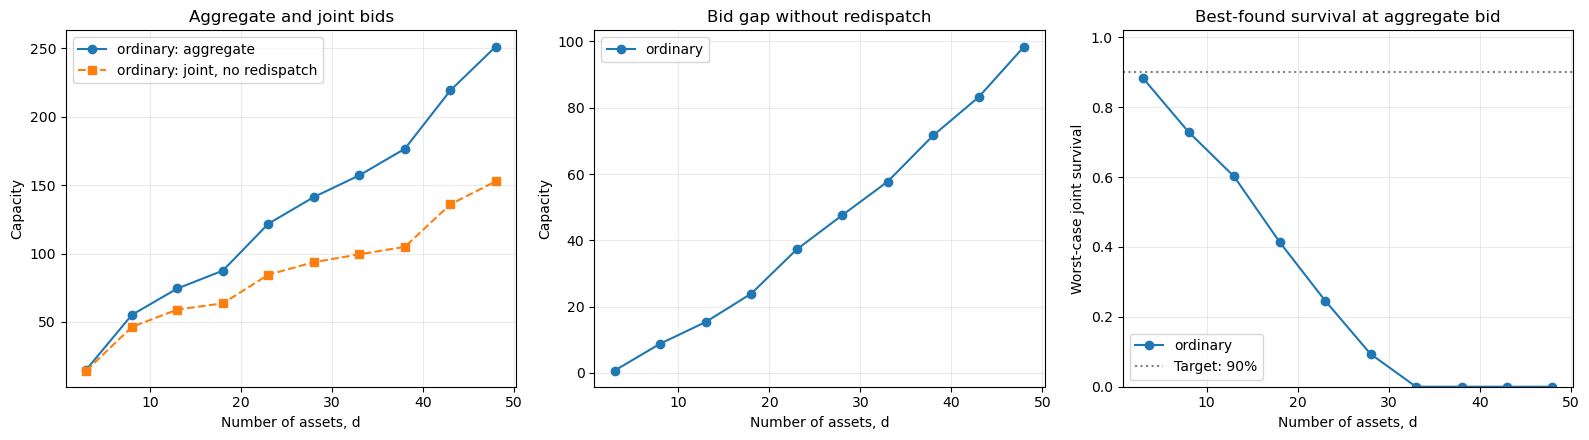

In [9]:
from matplotlib.ticker import PercentFormatter
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, data in sweep_results.groupby('scenario', sort=False):
    axes[0].plot(data['d'], data['b_agg'], 'o-', label=f'{name}: aggregate')
    axes[0].plot(data['d'], data['b_joint'], 's--', label=f'{name}: joint, no redispatch')
    axes[1].plot(data['d'], data['gap'], 'o-', label=name)
    axes[2].plot(data['d'], data['robust_survival'], 'o-', label=name)
axes[0].set(ylabel='Capacity', title='Aggregate and joint bids')
axes[1].set(ylabel='Capacity', title='Bid gap without redispatch')
axes[2].set(ylabel='Worst-case joint survival', title='Best-found survival at aggregate bid', ylim=(0, 1.02))
axes[2].axhline(alpha, color='grey', linestyle=':', label=f'Target: {alpha:.0%}')
# axes[2].yaxis.set_major_formatter(PercentFormatter(1.))
for ax in axes:
    ax.set_xlabel('Number of assets, d')
    ax.grid(alpha=.25)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Scenario comparison and interpretation

The robust dependence-independent allocation quantities are:

- $b_{\rm joint}^*$: maximum *simultaneously* deliverable bid using **one fixed allocation** at 90% worst-case joint reliability.
- $b_{\rm agg}^*$: Stage 1 worst-case VaR of the **aggregate capacity sum**, allowing ideal pooling.
- $\Delta b=b_{\rm agg}^*-b_{\rm joint}^*$: estimated loss of bidding capacity from prohibiting redispatch.
- $\underline S(\mathbf c_{\rm fixed}^*)$: best-found worst-case simultaneous reliability when the *full Stage 1 bid* is allocated without redispatch.

**Optimization distinction:** the fixed-sum optimization minimizes $\sum_i P(X_i<c_i)$; it is not solved by uniformly distributing extra capacity above a Gaussian-copula contour. The Fréchet bound is sharp for the chosen allocation and marginals, but the mixed-integer grid solver plus local polishing gives **numerical candidates**, not certificates of continuous global optimality. Compare with finer grids before interpreting small differences.

RA also yields a numerical bracket rather than an exact aggregate bid. Gaussian-copula and independent simulation comparisons continue to use the actual, transformed marginal distributions. No sequential redispatch is implemented yet.


In [10]:
comparison = pd.DataFrame([{
    'Scenario': name,
    'Comonotonic VaR': bids[name]['comonotonic'],
    'Independent VaR (MC)': bids[name]['independent'],
    'Gaussian-copula VaR (MC)': bids[name]['gaussian'],
    'Robust aggregate bid (RA lower)': allocations[name]['b_agg'],
    'RA upper': bids[name]['ra_upper'],
    'RA numerical gap': bids[name]['ra_gap'],
    'Robust joint bid, no redispatch (approx)': allocations[name]['b_joint'],
    'Bid gap, no redispatch (approx)': allocations[name]['gap'],
    'Risk at optimal joint bid': allocations[name]['joint_risk'],
    'Robust joint reliability at aggregate bid': allocations[name]['fixed_reliability']['worst'],
    'Gaussian-copula joint reliability at aggregate bid': allocations[name]['fixed_reliability']['gaussian'],
} for name in portfolios])
display(comparison)

# Confirm the optimization is numerically feasible for each scenario and respects atoms.
def validate():
    for name, ms in portfolios.items():
        assert len(ms) == d
        assert all(m.asset_type in ('ordinary', 'outage') for m in ms)
        assert np.array_equal([m.mu for m in ms], mu)
        assert np.array_equal([m.sd for m in ms], sd)
        for m in ms:
            expected = (stats.norm.cdf(-m.mu/m.sd)
                        if m.asset_type == 'ordinary' else p_outage)
            assert np.isclose(m.prob_zero, expected, atol=1e-12)
            assert m.cdf(-1) == 0 and m.cdf(0) == m.prob_zero
            assert m.failure(0) == 0
            u = np.unique(np.r_[0., np.linspace(.0001, .9999, 1000), m.prob_zero, 1.])
            q = m.ppf(u)
            assert np.all(q >= 0) and np.all(np.diff(q) >= -1e-10)
            assert np.all(m.cdf(q) >= u-1e-12)
            positive = (q > 0) & np.isfinite(q)
            assert np.allclose(m.cdf(q[positive]), u[positive], atol=1e-12)
        data = allocations[name]
        c_joint, c_fixed = data['joint_c'], data['fixed_c']
        assert np.all(c_joint >= 0) and np.all(c_fixed >= 0)
        assert failures(c_joint, ms).sum() <= eps+1e-8
        assert data['joint_reliability']['worst'] >= alpha-1e-8
        assert np.isclose(c_fixed.sum(), data['b_agg'], atol=1e-6)
        assert 0 <= data['fixed_reliability']['worst'] <= 1.
        assert data['fixed_reliability']['worst'] <= data['fixed_reliability']['gaussian']+1e-7
        assert data['b_joint'] <= data['b_agg']+1e-6
    check = np.random.default_rng(seed)
    assert np.array_equal(mu, check.normal(loc=10, scale=4, size=d))
    assert np.array_equal(sd, check.uniform(.5, 5, size=d))
    print('Validation passed: selected portfolios, exact zero atoms, and both robust Stage 2A allocations.')

validate()


,Scenario,Comonotonic VaR,Independent VaR (MC),Gaussian-copula VaR (MC),Robust aggregate bid (RA lower),RA upper,RA numerical gap,"Robust joint bid, no redispatch (approx)","Bid gap, no redispatch (approx)",Risk at optimal joint bid,Robust joint reliability at aggregate bid,Gaussian-copula joint reliability at aggregate bid
0,ordinary,331.030793,497.075084,389.329742,268.437695,268.470805,0.03311,160.399019,108.038675,0.099996,0.0,0.595283


Validation passed: selected portfolios, exact zero atoms, and both robust Stage 2A allocations.
